# ДЗ 2. Схема даних і feature store для ML-сценарію

Сценарій: автосервіс. Модель прогнозує, чи повернеться клієнт в автосервіс протягом 90 днів після моменту прогнозу (`returned_90d`).
Якщо ймовірність низька, клієнту можна відправити нагадування про ТО або знижку.

Центральна сутність для прогнозу - клієнт (`customer_id`). Ознаки рахуються з історії візитів його автомобілів.

## 0. Підготовка середовища

In [1]:
!pip install pixeltable-pgserver==0.5.0 jupysql psycopg2-binary -q

In [2]:
# імпорти
import os
import pixeltable_pgserver as pgserver
import graphviz
from sqlalchemy import create_engine
from IPython.display import Image, display

%load_ext sql

In [3]:
# запуск PostgreSQL і підключення
pgdata = os.path.abspath('pgdata')
srv = pgserver.get_server(pgdata, cleanup_mode='stop')
uri = srv.get_uri().replace('postgresql://', 'postgresql+psycopg2://')
engine = create_engine(uri)

%sql engine
%config SqlMagic.displaylimit = 50
%config SqlMagic.displaycon = False

In [4]:
%%sql
SELECT version();

1 rows affected.

version
"PostgreSQL 16.10 on x86_64-pc-linux-gnu, compiled by gcc (GCC) 14.2.1 20250110 (Red Hat 14.2.1-10), 64-bit"


## 1. ER-діаграма

Сутності предметної області:

- `hw2_customers` - клієнти автосервісу;
- `hw2_vehicles` - автомобілі клієнтів (у клієнта може бути кілька авто);
- `hw2_visits` - візити авто в сервіс;
- `hw2_services` - довідник послуг (заміна масла, діагностика і т.д.);
- `hw2_visit_services` - bridge-таблиця для зв'язку N:M між візитами і послугами. За один візит можна зробити кілька послуг, а одна послуга буває в багатьох візитах.

Feature store:

- offline: `hw2_customer_features_offline` (історія ознак з `valid_from` / `valid_to`) і `hw2_training_events` (момент прогнозу + label);
- online: `hw2_customer_features_online` (один рядок на клієнта з поточними ознаками).

Кардинальності:

| Зв'язок | Кардинальність | Обов'язковість |
|---|---|---|
| customers → vehicles | 1 : N | у клієнта 0..N авто, авто має рівно 1 власника |
| vehicles → visits | 1 : N | в авто 0..N візитів, візит має рівно 1 авто |
| visits ↔ services (через visit_services) | N : M | у візиті 1..N послуг, послуга в 0..N візитах |
| customers → customer_features_offline | 1 : N | у клієнта 0..N версій ознак |
| customers → training_events | 1 : N | у клієнта 0..N подій |
| customers → customer_features_online | 1 : 1 | у клієнта 0..1 рядок, рядок має рівно 1 клієнта |

Діаграма також збережена окремо: `er_diagram.png` і `er_diagram.dbml` (текстовий DSL для dbdiagram.io).

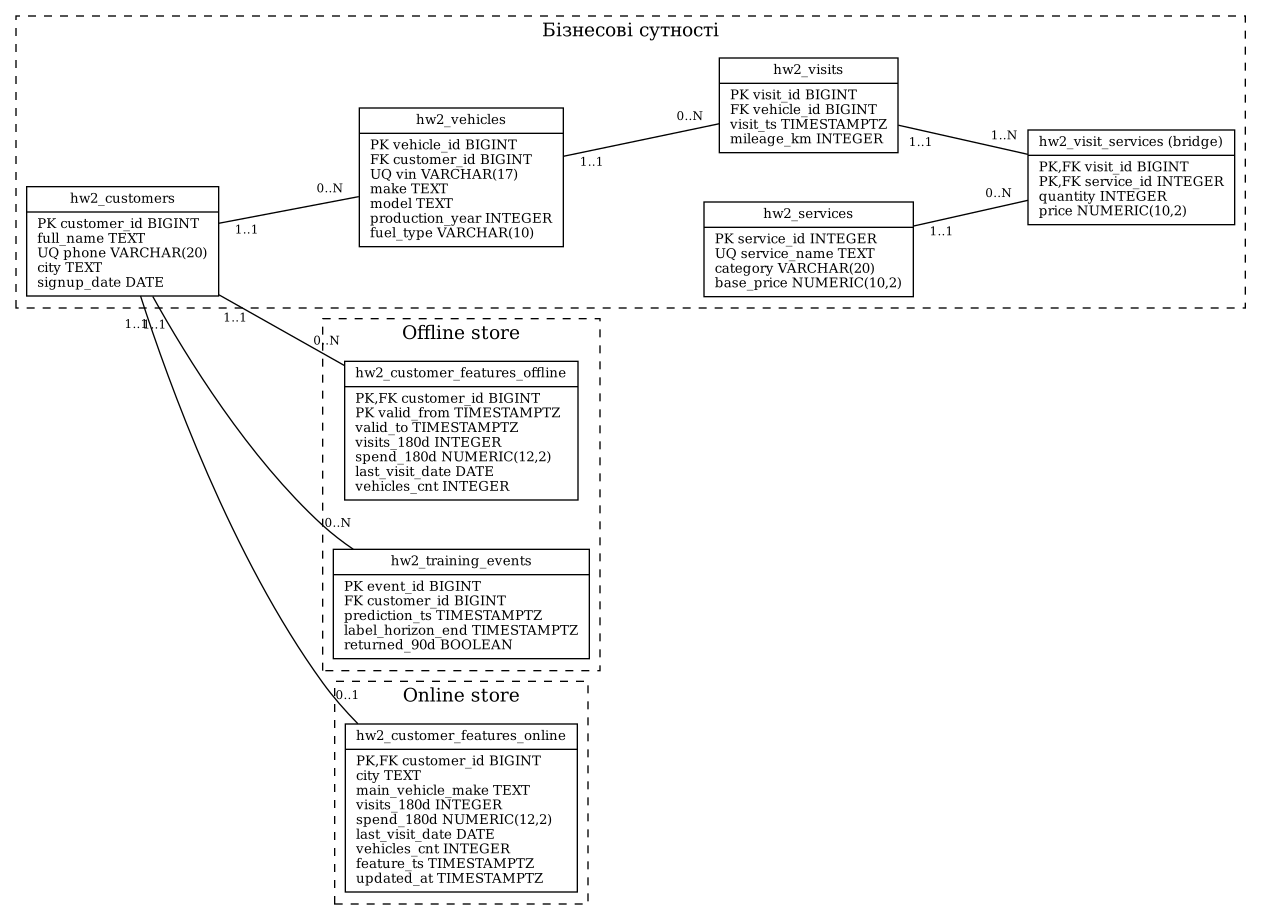

In [5]:
tables = {
    'customers': ['hw2_customers', 'PK customer_id BIGINT', 'full_name TEXT', 'UQ phone VARCHAR(20)', 'city TEXT', 'signup_date DATE'],
    'vehicles': ['hw2_vehicles', 'PK vehicle_id BIGINT', 'FK customer_id BIGINT', 'UQ vin VARCHAR(17)', 'make TEXT', 'model TEXT',
                 'production_year INTEGER', 'fuel_type VARCHAR(10)'],
    'visits': ['hw2_visits', 'PK visit_id BIGINT', 'FK vehicle_id BIGINT', 'visit_ts TIMESTAMPTZ', 'mileage_km INTEGER'],
    'visit_services': ['hw2_visit_services (bridge)', 'PK,FK visit_id BIGINT', 'PK,FK service_id INTEGER', 'quantity INTEGER', 'price NUMERIC(10,2)'],
    'services': ['hw2_services', 'PK service_id INTEGER', 'UQ service_name TEXT', 'category VARCHAR(20)', 'base_price NUMERIC(10,2)'],
    'feat_off': ['hw2_customer_features_offline', 'PK,FK customer_id BIGINT', 'PK valid_from TIMESTAMPTZ', 'valid_to TIMESTAMPTZ',
                 'visits_180d INTEGER', 'spend_180d NUMERIC(12,2)', 'last_visit_date DATE', 'vehicles_cnt INTEGER'],
    'events': ['hw2_training_events', 'PK event_id BIGINT', 'FK customer_id BIGINT', 'prediction_ts TIMESTAMPTZ',
               'label_horizon_end TIMESTAMPTZ', 'returned_90d BOOLEAN'],
    'feat_on': ['hw2_customer_features_online', 'PK,FK customer_id BIGINT', 'city TEXT', 'main_vehicle_make TEXT', 'visits_180d INTEGER',
                'spend_180d NUMERIC(12,2)', 'last_visit_date DATE', 'vehicles_cnt INTEGER', 'feature_ts TIMESTAMPTZ', 'updated_at TIMESTAMPTZ'],
}

groups = {
    'Бізнесові сутності': ['customers', 'vehicles', 'visits', 'visit_services', 'services'],
    'Offline store': ['feat_off', 'events'],
    'Online store': ['feat_on'],
}

er = graphviz.Digraph('er', format='png')
er.attr(rankdir='LR', nodesep='0.5', ranksep='1.2')
er.attr('node', shape='record', fontsize='10')
er.attr('edge', fontsize='9', arrowhead='none', labeldistance='2.2')

i = 0
for name, keys in groups.items():
    with er.subgraph(name='cluster_' + str(i)) as g:
        g.attr(label=name, style='dashed')
        for k in keys:
            cols = tables[k]
            label = cols[0] + '|' + '\\l'.join(cols[1:]) + '\\l'
            g.node(k, label)
    i += 1

er.edge('customers', 'vehicles', taillabel='1..1', headlabel='0..N')
er.edge('vehicles', 'visits', taillabel='1..1', headlabel='0..N')
er.edge('visits', 'visit_services', taillabel='1..1', headlabel='1..N')
er.edge('services', 'visit_services', taillabel='1..1', headlabel='0..N')
er.edge('customers', 'feat_off', taillabel='1..1', headlabel='0..N')
er.edge('customers', 'events', taillabel='1..1', headlabel='0..N')
er.edge('customers', 'feat_on', taillabel='1..1', headlabel='0..1')

er.render('er_diagram', cleanup=True)
display(Image('er_diagram.png'))

## 2. DDL у PostgreSQL

Спочатку видаляю всі таблиці, щоб notebook можна було запускати повторно.

In [6]:
%%sql
SET TIME ZONE 'UTC';

DROP TABLE IF EXISTS
    hw2_customer_features_online,
    hw2_training_events,
    hw2_customer_features_offline,
    hw2_visit_services,
    hw2_visits,
    hw2_services,
    hw2_vehicles,
    hw2_customers
CASCADE;

++
||
++
++

### Бізнесові сутності

In [7]:
%%sql
CREATE TABLE hw2_customers (
    customer_id BIGINT PRIMARY KEY,
    full_name   TEXT NOT NULL,
    phone       VARCHAR(20) NOT NULL UNIQUE,
    city        TEXT NOT NULL,
    signup_date DATE NOT NULL
);

CREATE TABLE hw2_vehicles (
    vehicle_id      BIGINT PRIMARY KEY,
    customer_id     BIGINT NOT NULL
        REFERENCES hw2_customers(customer_id),
    vin             VARCHAR(17) NOT NULL UNIQUE,
    make            TEXT NOT NULL,
    model           TEXT NOT NULL,
    production_year INTEGER NOT NULL
        CHECK (production_year BETWEEN 1980 AND 2026),
    fuel_type       VARCHAR(10) NOT NULL
        CHECK (fuel_type IN ('petrol', 'diesel', 'hybrid', 'electric', 'lpg'))
);

CREATE TABLE hw2_services (
    service_id   INTEGER PRIMARY KEY,
    service_name TEXT NOT NULL UNIQUE,
    category     VARCHAR(20) NOT NULL
        CHECK (category IN ('engine', 'electrical', 'brakes', 'tires', 'diagnostics')),
    base_price   NUMERIC(10, 2) NOT NULL
        CHECK (base_price >= 0)
);

CREATE TABLE hw2_visits (
    visit_id   BIGINT PRIMARY KEY,
    vehicle_id BIGINT NOT NULL
        REFERENCES hw2_vehicles(vehicle_id),
    visit_ts   TIMESTAMPTZ NOT NULL,
    mileage_km INTEGER NOT NULL
        CHECK (mileage_km >= 0)
);

-- bridge-таблиця N:M
CREATE TABLE hw2_visit_services (
    visit_id   BIGINT NOT NULL
        REFERENCES hw2_visits(visit_id),
    service_id INTEGER NOT NULL
        REFERENCES hw2_services(service_id),
    quantity   INTEGER NOT NULL DEFAULT 1
        CHECK (quantity > 0),
    price      NUMERIC(10, 2) NOT NULL
        CHECK (price >= 0),

    PRIMARY KEY (visit_id, service_id)
);

-- індекси для FK і для підрахунку ознак по візитах
CREATE INDEX hw2_idx_vehicles_customer ON hw2_vehicles (customer_id);
CREATE INDEX hw2_idx_visits_vehicle_ts ON hw2_visits (vehicle_id, visit_ts);

++
||
++
++

### Offline store

Ознаки клієнта:

- `visits_180d` - кількість візитів за останні 180 днів;
- `spend_180d` - сума витрат за останні 180 днів;
- `last_visit_date` - дата останнього візиту;
- `vehicles_cnt` - кількість авто клієнта.

Ознаки перераховуються нічним пайплайном після візиту, тому нова версія починається з 00:00 UTC наступного дня.
Версія діє на інтервалі `[valid_from, valid_to)`, `valid_to = NULL` означає поточну версію.

In [8]:
%%sql
CREATE TABLE hw2_customer_features_offline (
    customer_id     BIGINT NOT NULL
        REFERENCES hw2_customers(customer_id),
    valid_from      TIMESTAMPTZ NOT NULL,
    valid_to        TIMESTAMPTZ,
    visits_180d     INTEGER NOT NULL
        CHECK (visits_180d >= 0),
    spend_180d      NUMERIC(12, 2) NOT NULL
        CHECK (spend_180d >= 0),
    last_visit_date DATE,
    vehicles_cnt    INTEGER NOT NULL
        CHECK (vehicles_cnt >= 0),

    PRIMARY KEY (customer_id, valid_from),

    CHECK (valid_to IS NULL OR valid_to > valid_from)
);

-- PK (customer_id, valid_from) вже дає індекс для AS-OF пошуку.
-- Цей індекс гарантує, що в клієнта лише одна поточна версія,
-- і пришвидшує вибірку поточних ознак для оновлення online-таблиці.
CREATE UNIQUE INDEX hw2_idx_features_current
    ON hw2_customer_features_offline (customer_id)
    WHERE valid_to IS NULL;

CREATE TABLE hw2_training_events (
    event_id          BIGINT
        GENERATED BY DEFAULT AS IDENTITY
        PRIMARY KEY,
    customer_id       BIGINT NOT NULL
        REFERENCES hw2_customers(customer_id),
    prediction_ts     TIMESTAMPTZ NOT NULL,
    label_horizon_end TIMESTAMPTZ NOT NULL,
    returned_90d      BOOLEAN NOT NULL,

    UNIQUE (customer_id, prediction_ts),
    CHECK (label_horizon_end > prediction_ts)
);

++
||
++
++

### Online store

Один рядок на клієнта. Сюди додатково скопійовані `city` з `hw2_customers` і `main_vehicle_make` з `hw2_vehicles`,
щоб inference-сервіс отримував все одним запитом без JOIN.

In [9]:
%%sql
CREATE TABLE hw2_customer_features_online (
    customer_id       BIGINT PRIMARY KEY
        REFERENCES hw2_customers(customer_id),
    city              TEXT NOT NULL,
    main_vehicle_make TEXT,
    visits_180d       INTEGER NOT NULL
        CHECK (visits_180d >= 0),
    spend_180d        NUMERIC(12, 2) NOT NULL
        CHECK (spend_180d >= 0),
    last_visit_date   DATE,
    vehicles_cnt      INTEGER NOT NULL
        CHECK (vehicles_cnt >= 0),
    feature_ts        TIMESTAMPTZ NOT NULL,
    updated_at        TIMESTAMPTZ NOT NULL
        DEFAULT CURRENT_TIMESTAMP
);

++
||
++
++

Перевірка, що всі таблиці створились:

In [10]:
%%sql
SELECT table_name
FROM information_schema.tables
WHERE table_schema = 'public'
  AND table_name LIKE 'hw2_%'
ORDER BY table_name;

8 rows affected.

table_name
hw2_customer_features_offline
hw2_customer_features_online
hw2_customers
hw2_services
hw2_training_events
hw2_vehicles
hw2_visit_services
hw2_visits


## 3. Нормалізація

Таблиці `hw2_customers`, `hw2_vehicles`, `hw2_services`, `hw2_visits` і `hw2_visit_services` знаходяться в 3НФ. Усі значення атомарні (1НФ), наприклад послуги візиту не зберігаються списком в одній клітинці, а винесені в окрему таблицю. У `hw2_visit_services` ключ композитний (`visit_id`, `service_id`), і `quantity` та `price` залежать від усієї пари, тому 2НФ виконується. Назва послуги залежить лише від `service_id`, тому вона лежить у `hw2_services`.

Функціональні залежності, які я врахував:
`customer_id → full_name, phone, city, signup_date`;
`vehicle_id → customer_id, vin, make, model, production_year, fuel_type`;
`visit_id → vehicle_id, visit_ts, mileage_km`;
`service_id → service_name, category, base_price`;
`(visit_id, service_id) → quantity, price`.
У `hw2_visits` немає `customer_id`, бо `visit_id → vehicle_id → customer_id` була б транзитивною залежністю (порушення 3НФ). `price` у візиті - це не дубль `base_price`, а ціна на момент візиту, вона може відрізнятися через знижки.

Свідомо денормалізована таблиця - `hw2_customer_features_online`. У ній зберігаються агрегати з візитів і скопійовані `city` та `main_vehicle_make`. Сервісу прогнозу потрібен lookup за `customer_id` з мінімальною latency, і один рядок без JOIN тут кращий, ніж JOIN з чотирьох таблиць і агрегація на кожен запит.

Ризик: якщо клієнт змінить місто або купить нове авто, online-таблиця буде показувати старі дані, поки її не оновлять. Тому вона оновлюється з offline-джерела батчем після нічного перерахунку: береться поточна версія (`valid_to IS NULL`) і записується через `INSERT ... ON CONFLICT DO UPDATE`. Поле `feature_ts` показує, з якого моменту діють ознаки, а `updated_at` - коли рядок оновили, так можна контролювати свіжість.

## 4. Point-in-Time correctness

### Тестові дані

4 клієнти, 5 авто, 12 візитів. Історія ознак: 12 версій, для клієнта 1 - 4 версії, для клієнтів 2 і 3 - по 3 версії.

In [11]:
%%sql
INSERT INTO hw2_customers (customer_id, full_name, phone, city, signup_date)
VALUES
    (1, 'Олег Петренко',   '+48500100201', 'Bielsko-Biała', DATE '2024-02-20'),
    (2, 'Марта Ковальчук', '+48500100202', 'Kraków',        DATE '2024-04-10'),
    (3, 'Андрій Бондар',   '+48500100203', 'Katowice',      DATE '2024-05-01'),
    (4, 'Ірина Шевчук',    '+48500100204', 'Bielsko-Biała', DATE '2024-09-25');

INSERT INTO hw2_vehicles (vehicle_id, customer_id, vin, make, model, production_year, fuel_type)
VALUES
    (1, 1, 'TMBJJ7NE5J0123456', 'Skoda',   'Octavia', 2018, 'diesel'),
    (2, 1, 'VNKKD3D30KA654321', 'Toyota',  'Yaris',   2019, 'hybrid'),
    (3, 2, 'WVWZZZ3CZFE112233', 'VW',      'Passat',  2015, 'diesel'),
    (4, 3, 'VF1BZ0G0645778899', 'Renault', 'Megane',  2016, 'petrol'),
    (5, 4, 'WF0EXXGCDE4445566', 'Ford',    'Focus',   2014, 'lpg');

INSERT INTO hw2_services (service_id, service_name, category, base_price)
VALUES
    (1, 'Заміна масла і фільтрів',  'engine',      350.00),
    (2, 'Ремонт гальмівної системи', 'brakes',      480.00),
    (3, 'Комп''ютерна діагностика', 'diagnostics', 120.00),
    (4, 'Ремонт генератора',        'electrical',  900.00),
    (5, 'Шиномонтаж (1 колесо)',    'tires',        50.00);

4 rows affected.

5 rows affected.

5 rows affected.

++
||
++
++

In [12]:
%%sql
INSERT INTO hw2_visits (visit_id, vehicle_id, visit_ts, mileage_km)
VALUES
    (1,  1, TIMESTAMPTZ '2024-03-05 09:30:00+00', 152000),
    (2,  2, TIMESTAMPTZ '2024-06-10 14:00:00+00',  61000),
    (3,  1, TIMESTAMPTZ '2024-09-02 08:15:00+00', 161500),
    (4,  1, TIMESTAMPTZ '2025-01-20 11:00:00+00', 168200),
    (5,  3, TIMESTAMPTZ '2024-04-15 10:00:00+00', 240300),
    (6,  3, TIMESTAMPTZ '2024-08-20 12:30:00+00', 251000),
    (7,  3, TIMESTAMPTZ '2024-12-05 09:00:00+00', 259800),
    (8,  4, TIMESTAMPTZ '2024-05-12 13:00:00+00', 130400),
    (9,  4, TIMESTAMPTZ '2024-07-01 16:45:00+00', 133000),
    (10, 4, TIMESTAMPTZ '2025-02-10 10:20:00+00', 141900),
    (11, 5, TIMESTAMPTZ '2024-10-03 15:00:00+00', 198700),
    (12, 5, TIMESTAMPTZ '2025-03-01 09:40:00+00', 204100);

INSERT INTO hw2_visit_services (visit_id, service_id, quantity, price)
VALUES
    (1,  1, 1, 350.00), (1,  3, 1, 120.00),
    (2,  2, 1, 480.00),
    (3,  1, 1, 350.00),
    (4,  4, 1, 900.00), (4,  3, 1, 120.00),
    (5,  5, 4,  50.00),
    (6,  1, 1, 380.00), (6,  2, 1, 500.00),
    (7,  3, 1, 130.00),
    (8,  2, 1, 450.00),
    (9,  5, 4,  60.00),
    (10, 4, 1, 950.00),
    (11, 3, 1, 120.00), (11, 5, 4, 50.00),
    (12, 1, 1, 360.00);

12 rows affected.

16 rows affected.

++
||
++
++

Історія ознак. Кожна версія закривається рівно в момент, коли починається наступна (`valid_to` попередньої = `valid_from` наступної), тому проміжків і перекриттів немає.

In [13]:
%%sql
INSERT INTO hw2_customer_features_offline
    (customer_id, valid_from, valid_to, visits_180d, spend_180d, last_visit_date, vehicles_cnt)
VALUES
    -- клієнт 1: 4 версії
    (1, TIMESTAMPTZ '2024-03-06 00:00:00+00', TIMESTAMPTZ '2024-06-11 00:00:00+00', 1,  470.00, DATE '2024-03-05', 2),
    (1, TIMESTAMPTZ '2024-06-11 00:00:00+00', TIMESTAMPTZ '2024-09-03 00:00:00+00', 2,  950.00, DATE '2024-06-10', 2),
    (1, TIMESTAMPTZ '2024-09-03 00:00:00+00', TIMESTAMPTZ '2025-01-21 00:00:00+00', 2,  830.00, DATE '2024-09-02', 2),
    (1, TIMESTAMPTZ '2025-01-21 00:00:00+00', NULL,                                 2, 1370.00, DATE '2025-01-20', 2),
    -- клієнт 2: 3 версії
    (2, TIMESTAMPTZ '2024-04-16 00:00:00+00', TIMESTAMPTZ '2024-08-21 00:00:00+00', 1,  200.00, DATE '2024-04-15', 1),
    (2, TIMESTAMPTZ '2024-08-21 00:00:00+00', TIMESTAMPTZ '2024-12-06 00:00:00+00', 2, 1080.00, DATE '2024-08-20', 1),
    (2, TIMESTAMPTZ '2024-12-06 00:00:00+00', NULL,                                 2, 1010.00, DATE '2024-12-05', 1),
    -- клієнт 3: 3 версії
    (3, TIMESTAMPTZ '2024-05-13 00:00:00+00', TIMESTAMPTZ '2024-07-02 00:00:00+00', 1,  450.00, DATE '2024-05-12', 1),
    (3, TIMESTAMPTZ '2024-07-02 00:00:00+00', TIMESTAMPTZ '2025-02-11 00:00:00+00', 2,  690.00, DATE '2024-07-01', 1),
    (3, TIMESTAMPTZ '2025-02-11 00:00:00+00', NULL,                                 1,  950.00, DATE '2025-02-10', 1),
    -- клієнт 4: 2 версії
    (4, TIMESTAMPTZ '2024-10-04 00:00:00+00', TIMESTAMPTZ '2025-03-02 00:00:00+00', 1,  320.00, DATE '2024-10-03', 1),
    (4, TIMESTAMPTZ '2025-03-02 00:00:00+00', NULL,                                 2,  680.00, DATE '2025-03-01', 1);

12 rows affected.

++
||
++
++

In [14]:
%%sql
SELECT customer_id, COUNT(*) AS versions
FROM hw2_customer_features_offline
GROUP BY customer_id
ORDER BY customer_id;

4 rows affected.

customer_id,versions
1,4
2,3
3,3
4,2


Training events. `returned_90d` рахую з таблиці візитів: TRUE, якщо в інтервалі `(prediction_ts, label_horizon_end]` був хоча б один візит будь-якого авто клієнта.
Для label використання майбутніх даних нормальне, це і є те, що модель вчиться прогнозувати. А от ознаки мають бути тільки з минулого.

In [15]:
%%sql
INSERT INTO hw2_training_events (customer_id, prediction_ts, label_horizon_end, returned_90d)
SELECT
    p.customer_id,
    p.prediction_ts,
    p.prediction_ts + INTERVAL '90 days',
    EXISTS (
        SELECT 1
        FROM hw2_visits v
        JOIN hw2_vehicles vh ON vh.vehicle_id = v.vehicle_id
        WHERE vh.customer_id = p.customer_id
          AND v.visit_ts >  p.prediction_ts
          AND v.visit_ts <= p.prediction_ts + INTERVAL '90 days'
    )
FROM (
    VALUES
        (1, TIMESTAMPTZ '2024-03-01 00:00:00+00'),
        (1, TIMESTAMPTZ '2024-07-01 00:00:00+00'),
        (1, TIMESTAMPTZ '2024-10-01 00:00:00+00'),
        (1, TIMESTAMPTZ '2025-01-21 00:00:00+00'),
        (2, TIMESTAMPTZ '2024-06-01 00:00:00+00'),
        (2, TIMESTAMPTZ '2024-10-01 00:00:00+00'),
        (3, TIMESTAMPTZ '2024-08-01 00:00:00+00'),
        (3, TIMESTAMPTZ '2024-12-01 00:00:00+00'),
        (4, TIMESTAMPTZ '2024-11-01 00:00:00+00'),
        (4, TIMESTAMPTZ '2025-02-01 00:00:00+00')
) AS p (customer_id, prediction_ts);

SELECT * FROM hw2_training_events ORDER BY event_id;

10 rows affected.

10 rows affected.

event_id,customer_id,prediction_ts,label_horizon_end,returned_90d
1,1,2024-03-01 00:00:00+00:00,2024-05-30 00:00:00+00:00,True
2,1,2024-07-01 00:00:00+00:00,2024-09-29 00:00:00+00:00,True
3,1,2024-10-01 00:00:00+00:00,2024-12-30 00:00:00+00:00,False
4,1,2025-01-21 00:00:00+00:00,2025-04-21 00:00:00+00:00,False
5,2,2024-06-01 00:00:00+00:00,2024-08-30 00:00:00+00:00,True
6,2,2024-10-01 00:00:00+00:00,2024-12-30 00:00:00+00:00,True
7,3,2024-08-01 00:00:00+00:00,2024-10-30 00:00:00+00:00,False
8,3,2024-12-01 00:00:00+00:00,2025-03-01 00:00:00+00:00,True
9,4,2024-11-01 00:00:00+00:00,2025-01-30 00:00:00+00:00,False
10,4,2025-02-01 00:00:00+00:00,2025-05-02 00:00:00+00:00,True


### AS-OF запит 1: ознаки клієнта 1 на 2024-07-01 10:00 UTC

Має повернутись версія з 2024-06-11 (2 візити, 950). Версія з 2024-09-03 ще не існувала.

In [16]:
%%sql
SELECT
    customer_id,
    visits_180d,
    spend_180d,
    last_visit_date,
    valid_from,
    valid_to
FROM hw2_customer_features_offline
WHERE customer_id = 1
  AND valid_from <= TIMESTAMPTZ '2024-07-01 10:00:00+00'
  AND (
        valid_to > TIMESTAMPTZ '2024-07-01 10:00:00+00'
        OR valid_to IS NULL
      );

1 rows affected.

customer_id,visits_180d,spend_180d,last_visit_date,valid_from,valid_to
1,2,950.00,2024-06-10,2024-06-11 00:00:00+00:00,2024-09-03 00:00:00+00:00


### AS-OF запит 2: ознаки клієнта 1 рівно на межі 2025-01-21 00:00 UTC

У цей момент одна версія закінчується, а інша починається. Завдяки напіввідкритому інтервалу повертається рівно один рядок - нова версія.

In [17]:
%%sql
SELECT
    customer_id,
    visits_180d,
    spend_180d,
    last_visit_date,
    valid_from,
    valid_to
FROM hw2_customer_features_offline
WHERE customer_id = 1
  AND valid_from <= TIMESTAMPTZ '2025-01-21 00:00:00+00'
  AND (
        valid_to > TIMESTAMPTZ '2025-01-21 00:00:00+00'
        OR valid_to IS NULL
      );

1 rows affected.

customer_id,visits_180d,spend_180d,last_visit_date,valid_from,valid_to
1,2,1370.00,2025-01-20,2025-01-21 00:00:00+00:00,None


### AS-OF запит 3: зріз ознак усіх клієнтів на 2024-11-01

Так виглядав би feature store, якби ми дивились на нього 1 листопада 2024. Клієнт 4 має версію з 2024-10-04, а візит клієнта 2 від 2024-12-05 ще не врахований.

In [18]:
%%sql
SELECT
    customer_id,
    visits_180d,
    spend_180d,
    last_visit_date,
    valid_from
FROM hw2_customer_features_offline
WHERE valid_from <= TIMESTAMPTZ '2024-11-01 00:00:00+00'
  AND (
        valid_to > TIMESTAMPTZ '2024-11-01 00:00:00+00'
        OR valid_to IS NULL
      )
ORDER BY customer_id;

4 rows affected.

customer_id,visits_180d,spend_180d,last_visit_date,valid_from
1,2,830.00,2024-09-02,2024-09-03 00:00:00+00:00
2,2,1080.00,2024-08-20,2024-08-21 00:00:00+00:00
3,2,690.00,2024-07-01,2024-07-02 00:00:00+00:00
4,1,320.00,2024-10-03,2024-10-04 00:00:00+00:00


### AS-OF JOIN: формування training data

До кожної події приєднується лише та версія ознак, яка була чинною на `prediction_ts`.
Використовую `LEFT JOIN`, щоб не втратити події, для яких ознак ще немає. Подія 1 (клієнт 1, 2024-03-01) була до першого візиту, тому ознаки там NULL.

In [19]:
%%sql
SELECT
    e.event_id,
    e.customer_id,
    e.prediction_ts,
    e.returned_90d,
    f.visits_180d,
    f.spend_180d,
    f.last_visit_date,
    f.valid_from AS feature_valid_from
FROM hw2_training_events AS e
LEFT JOIN hw2_customer_features_offline AS f
    ON f.customer_id = e.customer_id
   AND f.valid_from <= e.prediction_ts
   AND (
        f.valid_to > e.prediction_ts
        OR f.valid_to IS NULL
       )
ORDER BY e.event_id;

10 rows affected.

event_id,customer_id,prediction_ts,returned_90d,visits_180d,spend_180d,last_visit_date,feature_valid_from
1,1,2024-03-01 00:00:00+00:00,True,None,None,None,None
2,1,2024-07-01 00:00:00+00:00,True,2,950.00,2024-06-10,2024-06-11 00:00:00+00:00
3,1,2024-10-01 00:00:00+00:00,False,2,830.00,2024-09-02,2024-09-03 00:00:00+00:00
4,1,2025-01-21 00:00:00+00:00,False,2,1370.00,2025-01-20,2025-01-21 00:00:00+00:00
5,2,2024-06-01 00:00:00+00:00,True,1,200.00,2024-04-15,2024-04-16 00:00:00+00:00
6,2,2024-10-01 00:00:00+00:00,True,2,1080.00,2024-08-20,2024-08-21 00:00:00+00:00
7,3,2024-08-01 00:00:00+00:00,False,2,690.00,2024-07-01,2024-07-02 00:00:00+00:00
8,3,2024-12-01 00:00:00+00:00,True,2,690.00,2024-07-01,2024-07-02 00:00:00+00:00
9,4,2024-11-01 00:00:00+00:00,False,1,320.00,2024-10-03,2024-10-04 00:00:00+00:00
10,4,2025-02-01 00:00:00+00:00,True,1,320.00,2024-10-03,2024-10-04 00:00:00+00:00


### Перевірка перекривних інтервалів (має бути 0 рядків)

In [20]:
%%sql
SELECT
    a.customer_id,
    a.valid_from AS a_from,
    a.valid_to   AS a_to,
    b.valid_from AS b_from,
    b.valid_to   AS b_to
FROM hw2_customer_features_offline AS a
JOIN hw2_customer_features_offline AS b
  ON a.customer_id = b.customer_id
 AND a.valid_from < COALESCE(b.valid_to, 'infinity'::timestamptz)
 AND b.valid_from < COALESCE(a.valid_to, 'infinity'::timestamptz)
 AND a.valid_from < b.valid_from;

customer_id,a_from,a_to,b_from,b_to


Додатково: кожна подія отримала не більше однієї версії ознак (має бути 0 рядків).

In [21]:
%%sql
SELECT e.event_id, COUNT(f.customer_id) AS matched_versions
FROM hw2_training_events AS e
LEFT JOIN hw2_customer_features_offline AS f
    ON f.customer_id = e.customer_id
   AND f.valid_from <= e.prediction_ts
   AND (f.valid_to > e.prediction_ts OR f.valid_to IS NULL)
GROUP BY e.event_id
HAVING COUNT(f.customer_id) > 1;

event_id,matched_versions


### Що буде з неправильним JOIN тільки за customer_id

Порівняю кількість рядків і скільки з них містять ознаки "з майбутнього".

In [22]:
%%sql
SELECT
    COUNT(*) AS rows_total,
    COUNT(DISTINCT e.event_id) AS events,
    SUM(CASE WHEN f.valid_from > e.prediction_ts THEN 1 ELSE 0 END) AS rows_from_future
FROM hw2_training_events AS e
JOIN hw2_customer_features_offline AS f
    ON f.customer_id = e.customer_id;

1 rows affected.

rows_total,events,rows_from_future
32,10,14


Приклад для події 1 (прогноз на 2024-03-01): неправильний JOIN приєднує всі 4 версії, хоча на той момент не було жодної.

In [23]:
%%sql
SELECT
    e.event_id,
    e.prediction_ts,
    f.valid_from,
    f.visits_180d,
    f.spend_180d,
    f.valid_from > e.prediction_ts AS from_future
FROM hw2_training_events AS e
JOIN hw2_customer_features_offline AS f
    ON f.customer_id = e.customer_id
WHERE e.event_id = 1
ORDER BY f.valid_from;

4 rows affected.

event_id,prediction_ts,valid_from,visits_180d,spend_180d,from_future
1,2024-03-01 00:00:00+00:00,2024-03-06 00:00:00+00:00,1,470.00,True
1,2024-03-01 00:00:00+00:00,2024-06-11 00:00:00+00:00,2,950.00,True
1,2024-03-01 00:00:00+00:00,2024-09-03 00:00:00+00:00,2,830.00,True
1,2024-03-01 00:00:00+00:00,2025-01-21 00:00:00+00:00,2,1370.00,True


### Пояснення

1. `valid_from <= prediction_ts` - версія ознак повинна вже існувати на момент прогнозу. Якщо версія почалась пізніше, у реальному житті ми б її ще не знали, і модель вчилась би на майбутньому.

2. `valid_to > prediction_ts OR valid_to IS NULL` - версія ще не повинна бути замінена іншою. `valid_to IS NULL` треба писати окремо, бо порівняння з NULL дає NULL, і поточна версія просто випала б з результату.

3. Напіввідкритий інтервал `[valid_from, valid_to)`: сусідні версії стикуються в одній точці (`valid_to` старої = `valid_from` нової). Якби межі були включні з обох боків, то на момент `2025-01-21 00:00` підійшли б дві версії і рядок задублювався. Запит 2 з напіввідкритим інтервалом повертає рівно один рядок. Якби виключні з обох боків, цей момент не потрапив би в жодну версію.

4. Без часового фільтра до кожної події приєднуються всі версії клієнта. У нас з 10 подій вийшло 32 рядки, і 14 з них з ознаками, які з'явились після `prediction_ts`. Наприклад, для прогнозу клієнта 1 на 2024-03-01 модель побачила б `spend_180d = 1370` з 2025 року і `last_visit_date` після моменту прогнозу. Особливо погано з `last_visit_date`: якщо вона пізніше за `prediction_ts`, це прямо підказує, що клієнт повернувся, тобто label протікає в ознаки. Модель на валідації показала б дуже високу якість, а в production, де майбутнього немає, працювала б значно гірше.

### Оновлення online-таблиці з offline-джерела

Беру поточну версію ознак, додаю місто і марку авто, з якою клієнт найчастіше приїжджає. Повторний запуск не створює дублікатів, бо використовується `ON CONFLICT`.

In [24]:
%%sql
WITH main_vehicle AS (
    SELECT DISTINCT ON (vh.customer_id)
        vh.customer_id,
        vh.make
    FROM hw2_vehicles vh
    LEFT JOIN hw2_visits v ON v.vehicle_id = vh.vehicle_id
    GROUP BY vh.customer_id, vh.vehicle_id, vh.make
    ORDER BY vh.customer_id, COUNT(v.visit_id) DESC, vh.vehicle_id
)
INSERT INTO hw2_customer_features_online
    (customer_id, city, main_vehicle_make, visits_180d, spend_180d,
     last_visit_date, vehicles_cnt, feature_ts, updated_at)
SELECT
    f.customer_id,
    c.city,
    mv.make,
    f.visits_180d,
    f.spend_180d,
    f.last_visit_date,
    f.vehicles_cnt,
    f.valid_from,
    CURRENT_TIMESTAMP
FROM hw2_customer_features_offline f
JOIN hw2_customers c ON c.customer_id = f.customer_id
LEFT JOIN main_vehicle mv ON mv.customer_id = f.customer_id
WHERE f.valid_to IS NULL
ON CONFLICT (customer_id) DO UPDATE SET
    city              = EXCLUDED.city,
    main_vehicle_make = EXCLUDED.main_vehicle_make,
    visits_180d       = EXCLUDED.visits_180d,
    spend_180d        = EXCLUDED.spend_180d,
    last_visit_date   = EXCLUDED.last_visit_date,
    vehicles_cnt      = EXCLUDED.vehicles_cnt,
    feature_ts        = EXCLUDED.feature_ts,
    updated_at        = EXCLUDED.updated_at;

4 rows affected.

++
||
++
++

Online lookup, який робив би inference-сервіс:

In [25]:
%%sql
SELECT *
FROM hw2_customer_features_online
WHERE customer_id = 1;

1 rows affected.

customer_id,city,main_vehicle_make,visits_180d,spend_180d,last_visit_date,vehicles_cnt,feature_ts,updated_at
1,Bielsko-Biała,Skoda,2,1370.00,2025-01-20,2,2025-01-21 00:00:00+00:00,2026-10-15 17:06:35.206018+00:00


## 5. Reflection

Найскладніше. Найбільше часу забрала point-in-time частина. Спочатку я хотів зробити ознаку `days_since_last_visit`, але зрозумів, що вона змінюється щодня, і тоді в історичній таблиці була б нова версія кожного дня. Тому замінив її на `last_visit_date`, а "скільки днів пройшло" можна порахувати вже на момент прогнозу. Ще довелось подумати над межами інтервалів: без напіввідкритого інтервалу запит рівно на момент зміни версії повертав би два рядки. Кардинальності тут були досить очевидні, найбільше сумнівався, чи треба `customer_id` у візитах, але вирішив, що ні, бо його можна отримати через авто.

Компроміси. Бізнесові таблиці нормалізовані до 3НФ, тому що вони постійно оновлюються (нові візити, зміна телефону, нове авто) і тут важливо, щоб кожен факт зберігався в одному місці. Offline feature-таблиця теж зберігає тільки ознаки й ключі, а історія робиться через версії. Online-таблиця денормалізована: там і агрегати, і місто, і марка авто. Її читають часто і за одним ключем, а оновлюють рідко, раз на ніч, тому дублювання тут себе виправдовує.

Якщо lookup має бути дуже швидким для великої кількості користувачів. Я б залишив той самий формат: один готовий денормалізований рядок на `customer_id`, ознаки заздалегідь матеріалізовані пайплайном. Далі можна винести online-рівень у key-value сховище типу Redis або додати кеш перед PostgreSQL, а читання розподілити по репліках або шардувати за `customer_id`. Обов'язково треба контролювати свіжість: дивитись на `feature_ts` і `updated_at` і ставити алерт, якщо дані давно не оновлювались.

Ризики еволюції схеми за пів року. Якщо перейменувати `spend_180d`, старий код моделі не знайде колонку. Якщо змінити тип, наприклад гроші з `NUMERIC` на копійки в `INTEGER`, назва та сама, а значення в 100 разів більші, і модель почне помилятись без жодної помилки в коді. Те саме зі зміною семантики, наприклад вікно 180 днів замінити на 90. Такі зміни краще робити через нову колонку (`spend_90d` або `spend_180d_v2`) і міграції. Видаляти колонку можна лише тоді, коли жодна модель її вже не використовує, бо в production може одночасно працювати стара і нова версія моделі.